# Graph Engineering & Baselines

Build k-NN and SNN graphs and evaluate **MLP as the core baseline** at two training-label budgets. Label Propagation provides an additional graph-based comparison.

The proposed GNN comparison is developed separately. Run all sections here to complete MLP and Label Propagation at both budgets.

Run `01-data_processing.ipynb` first, then run this notebook from the repository root with the **graph-ml** kernel. Outputs go to **`data/graph_engineering/`**.

See the [walkthrough](markdown/graph_engineering_walkthrough.md) for run instructions and export details.

## 1. Settings and evaluation protocol

Use seed **42** and the existing **60/20/20 train/validation/test** split. All cells stay in the graph. Only selected training labels are available for fitting.

| Label budget | Training labels | Current count |
|---|---|---|
| `5pct` | 5% of each training class, rounded up | 1,971 cells, about 3% overall |
| `full` | Entire training pool | 39,346 cells, about 60% overall |

The small budget is about 3% overall because 5% × 60% = 3%. Train models separately at each budget with fixed graphs and validation/test masks.

### Label leakage checks

All cells' features and edges are available in this transductive experiment. Edges may cross the split boundaries. Labels follow different rules:

- **Training:** fit MLP only on `labelled_train`. Label Propagation receives training labels with **-1 everywhere else**. A GNN must compute loss only on `labelled_train`.
- **Validation:** use labels for scores, MLP width and checkpoint selection. Never supply them as training targets or propagation seeds.
- **Test:** keep scoring off until settings are fixed. Test targets are not exported for GNN training and must not guide model selection.

Check that split masks are disjoint and that `labelled_train` stays inside the training pool. k-NN and SNN use PCA distances and neighbour overlap, never cell types. Homophily is analysis only and must not enter model features or a GNN gate. Fit each scaler only on the selected training cells.

Stratification and per-class sampling use labels to define the split and budget. PCA and gene selection may use all cells' expression values under this protocol. The original metadata still contains held-out labels. Masks specify which labels each step may use. Earlier label-based QC, exploratory analysis and test inspection still affect evaluation independence.

See the [walkthrough](markdown/graph_engineering_walkthrough.md#how-the-transductive-split-prevents-label-leakage) for the label-use table and GNN loss example.

In [1]:
from pathlib import Path
import copy
import hashlib
import inspect
import json
import ast
import platform
import time
import warnings
import shutil
from importlib.metadata import version

import anndata as ad
import igraph as ig
import joblib
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.semi_supervised import LabelPropagation
from sklearn.utils.class_weight import compute_sample_weight
from threadpoolctl import threadpool_limits
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data/processed"
NOTEBOOK = ROOT / "02-graph_engineering_baselines.ipynb"
SEED = 42
N_PCS = 50
K = 15
QUERY_BATCH_SIZE = 1024
SNN_EDGE_BATCH_SIZE = 4096
CPU_THREADS = 4
MLP_WIDTHS = (64, 128)
MLP_SEEDS = (42, 123, 2024)  # same seeds as the GNN runs in notebook 03
MAX_EPOCHS = 200
PATIENCE = 25
LP_MAX_ITER = 2000
LP_TOL = 1e-3
EVALUATE_TEST = False

MLP_SETTINGS = dict(activation="relu", solver="adam", alpha=1e-4, batch_size=256,
                    learning_rate_init=1e-3, early_stopping=False, random_state=SEED, shuffle=True)
VERSIONS = {p: version(p) for p in ["numpy", "scipy", "pandas", "scikit-learn", "anndata", "igraph"]}
assert "sample_weight" in inspect.signature(MLPClassifier.partial_fit).parameters
assert SEED in MLP_SEEDS, "The exported MLP is the SEED run"
print("Python:", platform.python_version())
display(pd.Series(VERSIONS, name="version"))

Python: 3.11.18


numpy             2.4.6
scipy            1.17.1
pandas            2.3.3
scikit-learn      1.9.1
anndata         0.12.19
igraph            1.0.0
Name: version, dtype: object

In [2]:
def digest_array(values):
    values = np.ascontiguousarray(values)
    h = hashlib.sha256(str((values.shape, values.dtype.str)).encode())
    h.update(memoryview(values).cast("B"))
    return h.hexdigest()

def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def file_digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)

## 2. Load features and masks

Check the files in `data/processed/` against `work_processed.h5ad`, including cell order and split masks. Use only the first **50 PCs** as features.

Encode classes from the training pool. Training targets are **-1** outside selected training cells. Store validation targets separately and encode test targets only for final scoring.

In [3]:
required = ["X_pca.npy", "cell_metadata.csv", "connectivities.npz", "work_processed.h5ad"]
for name in required:
    if not (DATA / name).is_file():
        raise FileNotFoundError(f"Missing {name}; run 01-data_processing.ipynb first.")
input_hashes = {name: file_digest(DATA / name) for name in required}
meta = pd.read_csv(DATA / "cell_metadata.csv", index_col=0)
pca = np.load(DATA / "X_pca.npy", allow_pickle=False)
A_reference = sp.load_npz(DATA / "connectivities.npz").tocsr()
assert meta.index.is_unique and pca.ndim == 2 and pca.shape[1] >= N_PCS
assert len(meta) == len(pca) and np.isfinite(pca).all()
for name in ["train_mask", "val_mask", "test_mask"]:
    assert meta[name].dtype == bool
train_pool, val_mask, test_mask = [meta[name].to_numpy() for name in ["train_mask", "val_mask", "test_mask"]]
assert np.all(train_pool.astype(int) + val_mask.astype(int) + test_mask.astype(int) == 1)
assert all(m.any() for m in [train_pool, val_mask, test_mask])
work = ad.read_h5ad(DATA / "work_processed.h5ad", backed="r")
try:
    assert np.array_equal(work.obs_names.astype(str), meta.index.astype(str))
    assert np.array_equal(work.obsm["X_pca"][:, :N_PCS], pca[:, :N_PCS])
    assert (work.obsp["connectivities"] != A_reference).nnz == 0
    for name in ["train_mask", "val_mask", "test_mask"]:
        assert np.array_equal(meta[name], work.obs[name])
    known = train_pool | val_mask
    assert np.array_equal(meta.loc[known, "celltype"].astype(str), work.obs.loc[known, "celltype"].astype(str))
finally:
    work.file.close()
X = np.ascontiguousarray(pca[:, :N_PCS], dtype=np.float32)
encoder = LabelEncoder().fit(meta.loc[train_pool, "celltype"])
class_names = encoder.classes_
class_ids = np.arange(len(class_names))
y_pool = np.full(len(X), -1, dtype=np.int64)
y_pool[train_pool] = encoder.transform(meta.loc[train_pool, "celltype"])
y_val = encoder.transform(meta.loc[val_mask, "celltype"])
validation_labels = np.full(len(X), -1, dtype=np.int64)
validation_labels[val_mask] = y_val
print(f"Cells: {len(X):,}; PCs: {N_PCS}; classes: {len(class_names)}")
print({"train_pool": int(train_pool.sum()), "validation": int(val_mask.sum()), "test": int(test_mask.sum())})

Cells: 65,578; PCs: 50; classes: 11
{'train_pool': 39346, 'validation': 13116, 'test': 13116}


In [4]:
def select_training_labels(labels, pool, *, fraction=None, per_class=None, seed=42):
    labels, pool = np.asarray(labels), np.asarray(pool)
    if labels.ndim != 1 or pool.dtype != bool or pool.shape != labels.shape:
        raise ValueError("Expected nonmissing one-dimensional labels and a matching boolean pool mask")
    if pd.isna(labels[pool]).any():
        raise ValueError("Training-pool labels must not be missing")
    if (fraction is None) == (per_class is None):
        raise ValueError("Choose exactly one of fraction or per_class")
    if fraction is not None and not 0 < fraction <= 1:
        raise ValueError("fraction must be in (0, 1]")
    if per_class is not None and (not isinstance(per_class, (int, np.integer)) or per_class < 1):
        raise ValueError("per_class must be a positive integer")
    if not pool.any() or (labels[pool] < 0).any():
        raise ValueError("Training pool needs nonnegative encoded labels")
    rng = np.random.default_rng(seed)
    selected = np.zeros(len(labels), dtype=bool)
    for c in np.unique(labels[pool]):
        candidates = np.flatnonzero(pool & (labels == c))
        count = per_class if per_class is not None else max(1, int(np.ceil(len(candidates) * fraction)))
        if count > len(candidates):
            raise ValueError(f"Class {c} has only {len(candidates)} training cells; requested {count}")
        selected[rng.permutation(candidates)[:count]] = True
    return selected

budget_masks = {
    "5pct": select_training_labels(y_pool, train_pool, fraction=0.05, seed=SEED),
    "full": train_pool.copy(),
}
training_labels = {name: np.where(mask, y_pool, -1) for name, mask in budget_masks.items()}
for name, mask in budget_masks.items():
    assert np.all(~mask | train_pool)
    assert not (mask & (val_mask | test_mask)).any()
    assert (training_labels[name][~mask] == -1).all()
    assert set(training_labels[name][mask]) == set(class_ids)
display(pd.DataFrame({name: np.bincount(labels[budget_masks[name]], minlength=len(class_ids))
                      for name, labels in training_labels.items()}, index=class_names))

source_cells = nbformat.read(NOTEBOOK, as_version=4).cells
# Test scoring is a reporting switch, not a new training configuration.
code_parts = []
for cell in source_cells:
    if cell.cell_type == "code":
        tree = ast.parse(cell.source)
        tree.body = [node for node in tree.body if not (
            isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == "EVALUATE_TEST" for t in node.targets))]
        code_parts.append(ast.dump(tree, include_attributes=False))
code_sha256 = digest_json(code_parts)
export_spec = {
    "schema": 1, "protocol": "transductive", "seed": SEED, "n_pcs": N_PCS, "k": K,
    "knn": "exact Euclidean; 15 other neighbours; binary union", "snn": "Jaccard on union-kNN candidates; drop zero overlap",
    "self_loops": False, "normalised": False, "query_batch_size": QUERY_BATCH_SIZE,
    "input_hashes": input_hashes, "features_sha256": digest_array(X),
    "cell_ids_sha256": digest_json(meta.index.astype(str).tolist()), "code_sha256": code_sha256,
    "mask_hashes": {name: digest_array(mask) for name, mask in budget_masks.items()},
    "label_hashes": {name: digest_array(labels) for name, labels in training_labels.items()},
    "validation_mask_sha256": digest_array(val_mask), "test_mask_sha256": digest_array(test_mask),
    "mlp_widths": list(MLP_WIDTHS), "mlp_seeds": list(MLP_SEEDS), "mlp_settings": MLP_SETTINGS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "lp_max_iter": LP_MAX_ITER, "lp_tol": LP_TOL,
    "versions": VERSIONS, "python": platform.python_version(),
}
def prepare_export_directory(folder, spec):
    """Keep one export folder; rebuild its generated files when the spec changes."""
    folder = Path(folder)
    if folder.is_symlink():
        raise ValueError("The export directory must not be a symbolic link")
    folder.mkdir(parents=True, exist_ok=True)
    subdirs = ["graphs", "analysis", "results", "models", "labels_5pct", "labels_full"]
    for name in subdirs:
        if (folder / name).is_symlink():
            raise ValueError(f"Export subdirectory must not be a symbolic link: {name}")
    manifest_path = folder / "manifest.json"
    previous = json.loads(manifest_path.read_text()) if manifest_path.exists() else None
    reusable = (previous is not None and previous["spec"] == spec
                and previous.get("graph_exports_complete", False))
    if reusable:
        for relative, expected in previous.get("files_sha256", {}).items():
            path = folder / relative
            if Path(relative).is_absolute() or ".." in Path(relative).parts or not path.resolve().is_relative_to(folder.resolve()):
                raise ValueError(f"Invalid manifest path: {relative}")
            if not path.is_file() or file_digest(path) != expected:
                raise ValueError(f"Saved export changed: {relative}. Restore it before reusing this cache.")
        print("Reusing matching graph exports.")
    else:
        # Mark incomplete before cleanup so an interrupted rebuild can be retried.
        write_json(manifest_path, {"spec": spec, "graph_exports_complete": False,
                   "baselines_complete": False, "files_sha256": {}})
        for name in subdirs:
            path = folder / name
            if path.exists():
                shutil.rmtree(path)
        for name in ["cell_ids.csv", "class_names.json", "X_pca.npy"]:
            path = folder / name
            if path.exists():
                path.unlink()
        print("Building the current export; previous generated files replaced.")
    # Old test reports must not look like results from the new execution.
    for name in ["test_results.csv", "test_per_class.csv"]:
        path = folder / "results" / name
        if path.exists():
            path.unlink()
    for name in subdirs:
        (folder / name).mkdir(parents=True, exist_ok=True)
    return manifest_path

configuration_id = digest_json(export_spec)[:12]  # recorded identity, not a folder name
OUT = ROOT / "data/graph_engineering"
manifest_path = prepare_export_directory(OUT, export_spec)
print("Output:", OUT.relative_to(ROOT))

,5pct,full
CD14+ Monocyte,83,1642
CD19+ B,168,3360
CD34+,8,155
CD4+ T Helper2,3,55
CD4+/CD25 T Reg,177,3538
CD4+/CD45RA+/CD25- Naive T,54,1080
CD4+/CD45RO+ Memory,88,1758
CD56+ NK,253,5054
CD8+ Cytotoxic T,597,11935
CD8+/CD45RA+ Naive Cytotoxic,481,9604


Building the current export; previous generated files replaced.
Output: data/graph_engineering


## 3. Batched k-NN graph

Find each cell's **15 nearest other cells** by exact Euclidean search on the original PCA coordinates. Each batch searches all cells. Exclude the cell itself, but keep other cells with identical coordinates.

Keep an undirected edge if either cell selects the other, with weight 1. Degree can reach 123 if a cell selects 15 neighbours and 108 additional cells select it. **15 limits selections, not final degree.**

Save neighbour indices, distances and sparse adjacency without self-loops or GNN normalisation.

In [5]:
def build_knn_graph(features, k=15, batch_size=1024, threads=4, progress=False):
    features = np.asarray(features)
    if features.ndim != 2 or not np.isfinite(features).all():
        raise ValueError("Expected a finite feature matrix")
    n = len(features)
    if not isinstance(k, (int, np.integer)) or not 1 <= k < n:
        raise ValueError("Need integer 1 <= k < number of cells")
    if not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
        raise ValueError("batch_size must be a positive integer")
    search = NearestNeighbors(n_neighbors=k + 1, algorithm="brute", metric="euclidean", n_jobs=1)
    search.fit(features)  # no labels passed
    indices = np.empty((n, k), dtype=np.int32)
    distances = np.empty((n, k), dtype=np.float32)
    with threadpool_limits(limits=threads):
        for start in range(0, n, batch_size):
            stop = min(start + batch_size, n)
            d, idx = search.kneighbors(features[start:stop])
            for row, cell in enumerate(range(start, stop)):
                other = idx[row] != cell
                candidate, distance = idx[row, other], d[row, other]
                order = np.lexsort((candidate, distance))[:k]
                indices[cell], distances[cell] = candidate[order], distance[order]
            if progress and (start == 0 or stop == n or start // batch_size % 16 == 0):
                print(f"Neighbours: {stop:,}/{n:,}", flush=True)
    rows = np.repeat(np.arange(n), k)
    directed = sp.csr_matrix((np.ones(n * k, dtype=np.float32),
                            (rows, indices.ravel())), shape=(n, n))
    graph = directed.maximum(directed.T).tocsr()
    graph.setdiag(0)
    graph.eliminate_zeros()
    assert np.all(np.diff(directed.indptr) == k)
    assert not np.any(indices == np.arange(n)[:, None])
    assert graph.diagonal().sum() == 0 and (graph != graph.T).nnz == 0
    return graph, indices, distances

def validate_knn_result(graph, indices, distances, n, k):
    if graph.shape != (n, n) or indices.shape != (n, k) or distances.shape != (n, k):
        raise ValueError("Cached graph or neighbours have incorrect dimensions")
    if not np.issubdtype(indices.dtype, np.integer) or (indices < 0).any() or (indices >= n).any():
        raise ValueError("Invalid neighbour indices")
    if (indices == np.arange(n)[:, None]).any() or (np.diff(np.sort(indices, axis=1), axis=1) == 0).any():
        raise ValueError("Self-neighbours or duplicate neighbour indices")
    if not np.isfinite(distances).all() or (distances < 0).any():
        raise ValueError("Invalid neighbour distances")
    directed = sp.csr_matrix((np.ones(n * k), (np.repeat(np.arange(n), k), indices.ravel())), shape=(n, n))
    if (graph != directed.maximum(directed.T)).nnz:
        raise ValueError("Adjacency does not match the binary union of saved neighbours")

start = time.perf_counter()
knn_path = OUT / "graphs/knn_adjacency.npz"
if knn_path.exists():
    A_knn = sp.load_npz(knn_path).tocsr()
    neighbour_indices = np.load(OUT / "graphs/neighbour_indices.npy", allow_pickle=False)
    neighbour_distances = np.load(OUT / "graphs/neighbour_distances.npy", allow_pickle=False)
else:
    A_knn, neighbour_indices, neighbour_distances = build_knn_graph(
        X, k=K, batch_size=QUERY_BATCH_SIZE, threads=CPU_THREADS, progress=True)
    sp.save_npz(knn_path, A_knn)
    np.save(OUT / "graphs/neighbour_indices.npy", neighbour_indices)
    np.save(OUT / "graphs/neighbour_distances.npy", neighbour_distances)
validate_knn_result(A_knn, neighbour_indices, neighbour_distances, len(X), K)
print(f"k-NN ready in {time.perf_counter() - start:.1f}s; {A_knn.nnz // 2:,} edges.")

Neighbours: 1,024/65,578


Neighbours: 17,408/65,578


Neighbours: 33,792/65,578


Neighbours: 50,176/65,578


Neighbours: 65,578/65,578


k-NN ready in 4.9s; 819,262 edges.


## 4. Shared nearest-neighbour graph

Weight each k-NN edge by the **Jaccard overlap** of the two original neighbour lists:

**weight = shared neighbours / distinct neighbours across both lists**

Two lists of 15 sharing 10 neighbours have weight 10 / (15 + 15 − 10) = 0.5.

Remove zero-overlap edges and keep all cells. Add no new edges. Process edges in batches to limit memory use. Keep the Scanpy graph from preprocessing as a reference because its construction differs.

In [6]:
def build_snn_graph(neighbours, candidate_graph, edge_batch_size=4096):
    neighbours = np.asarray(neighbours)
    n, k = neighbours.shape
    if edge_batch_size < 1 or candidate_graph.shape != (n, n):
        raise ValueError("Invalid edge batch size or candidate shape")
    upper = sp.triu(candidate_graph, k=1).tocoo()
    weights = np.empty(upper.nnz, dtype=np.float32)
    for start in range(0, upper.nnz, edge_batch_size):
        end = min(start + edge_batch_size, upper.nnz)
        left = neighbours[upper.row[start:end]]
        right = neighbours[upper.col[start:end]]
        shared = (left[:, :, None] == right[:, None, :]).sum(axis=(1, 2))
        weights[start:end] = shared / (2 * k - shared)
    upper_weighted = sp.csr_matrix((weights, (upper.row, upper.col)), shape=(n, n))
    graph = (upper_weighted + upper_weighted.T).tocsr()
    graph.eliminate_zeros()
    return graph

snn_path = OUT / "graphs/snn_adjacency.npz"
if snn_path.exists():
    A_snn = sp.load_npz(snn_path).tocsr()
else:
    A_snn = build_snn_graph(neighbour_indices, A_knn, SNN_EDGE_BATCH_SIZE)
    sp.save_npz(snn_path, A_snn)
assert (A_snn != A_snn.T).nnz == 0 and not A_snn.diagonal().any()
assert A_snn.shape == A_knn.shape
assert (A_snn - A_snn.multiply(A_knn)).nnz == 0
assert np.all((A_snn.data > 0) & (A_snn.data <= 1))
graphs = {"knn": A_knn, "snn": A_snn, "scanpy_reference": A_reference}
print(f"SNN: {A_snn.nnz // 2:,} edges; removed {(A_knn.nnz - A_snn.nnz) // 2:,} zero-overlap edges.")

SNN: 666,355 edges; removed 152,907 zero-overlap edges.


## 5. Graph checks and statistics

Check symmetry, self-loops, neighbour lists and SNN weights. Compare degrees, components, isolated cells and clustering without using labels.

**Degree** counts neighbours. **Strength** sums edge weights. **Clustering** measures connections among a cell's neighbours. Here clustering ignores weights and is zero for cells with fewer than two neighbours.

Passed graph, SNN and held-out-label sampling checks.


,nodes,edges,degree_min,degree_mean,degree_max,isolates,components,largest_component_fraction,mean_local_clustering,strength_mean,strength_max,edge_weight_min,edge_weight_median,edge_weight_max
knn,65578.0,819262.0,15.0,24.985879,123.0,0.0,1.0,1.00000,0.187686,24.985880,123.000000,1.000000e+00,1.000000,1.000
snn,65578.0,666355.0,0.0,20.322517,119.0,2.0,3.0,0.99997,0.241307,3.281601,31.125862,3.448276e-02,0.111111,0.875
scanpy_reference,65578.0,764669.0,14.0,23.320900,121.0,0.0,1.0,1.00000,0.202097,11.974853,62.983665,6.558077e-43,0.323915,1.000


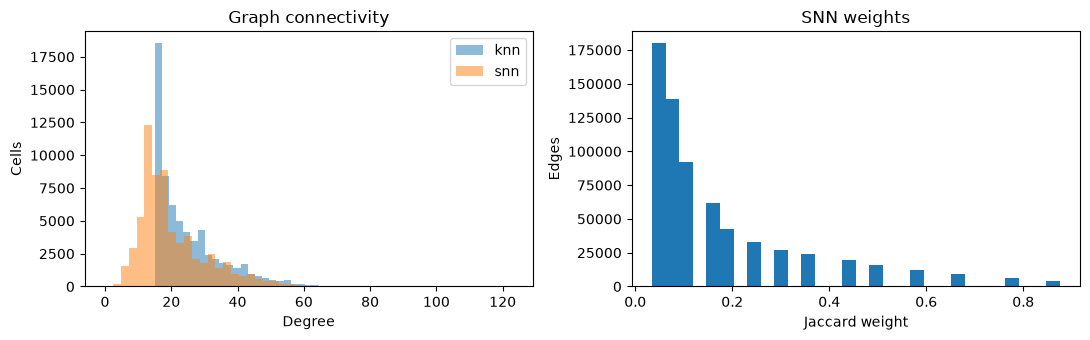

In [7]:
def checked_graph(graph):
    graph = sp.csr_matrix(graph, dtype=np.float64, copy=True)
    graph.sum_duplicates()
    graph.eliminate_zeros()
    if graph.shape[0] != graph.shape[1] or not graph.shape[0]:
        raise ValueError("Expected nonempty square adjacency")
    if not np.isfinite(graph.data).all() or (graph.data < 0).any():
        raise ValueError("Invalid edge weights")
    if np.any(graph.diagonal()):
        raise ValueError("Remove self-loops before the audit")
    difference = graph - graph.T
    if difference.nnz:
        raise ValueError("Expected a symmetric graph")
    return graph

def graph_statistics(graph):
    graph = checked_graph(graph)
    degree = np.diff(graph.indptr)
    components, membership = connected_components(graph, directed=False)
    upper = sp.triu(graph, k=1).tocoo()
    graph_ig = ig.Graph(n=graph.shape[0], edges=list(zip(upper.row.tolist(), upper.col.tolist())), directed=False)
    clustering = np.asarray(graph_ig.transitivity_local_undirected(mode="zero"))
    return {"nodes": graph.shape[0], "edges": graph.nnz // 2,
            "degree_min": int(degree.min()), "degree_mean": float(degree.mean()),
            "degree_max": int(degree.max()), "isolates": int((degree == 0).sum()),
            "components": int(components),
            "largest_component_fraction": float(np.bincount(membership).max() / len(degree)),
            "mean_local_clustering": float(clustering.mean())}

def graph_summary(graph):
    result = graph_statistics(graph)
    weights = sp.triu(graph, k=1).data
    strength = np.asarray(graph.sum(axis=1)).ravel()
    result.update(strength_mean=float(strength.mean()), strength_max=float(strength.max()))
    for name, q in [("min", 0), ("median", 0.5), ("max", 1)]:
        result["edge_weight_" + name] = float(np.quantile(weights, q)) if len(weights) else np.nan
    return result

toy_x = np.array([[0.], [0.], [2.], [5.]], dtype=np.float32)
toy_a, toy_idx, toy_dist = build_knn_graph(toy_x, k=2, batch_size=2)
validate_knn_result(toy_a, toy_idx, toy_dist, 4, 2)
assert 1 in toy_idx[0] and 0 in toy_idx[1]
toy_snn = build_snn_graph(toy_idx, toy_a, edge_batch_size=1)
for i, j in zip(*sp.triu(toy_a, k=1).nonzero()):
    left, right = set(toy_idx[i]), set(toy_idx[j])
    assert np.isclose(toy_snn[i, j], len(left & right) / len(left | right))
assert (toy_snn != toy_snn.T).nnz == 0
np.testing.assert_array_equal(toy_a.toarray(), build_knn_graph(toy_x, k=2, batch_size=4)[0].toarray())
toy_y = np.repeat([0, 1], 6)
toy_pool = np.tile([True, True, True, True, False, False], 2)
small = select_training_labels(toy_y, toy_pool, per_class=1, seed=SEED)
perturbed = toy_y.copy(); perturbed[~toy_pool] = 999
np.testing.assert_array_equal(small, select_training_labels(perturbed, toy_pool, per_class=1, seed=SEED))
print("Passed graph, SNN and held-out-label sampling checks.")

graph_stats = pd.DataFrame({name: graph_summary(a) for name, a in graphs.items()}).T
graph_stats.to_csv(OUT / "analysis/graph_statistics.csv", index_label="graph")
display(graph_stats)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name in ["knn", "snn"]:
    axes[0].hist(np.diff(graphs[name].indptr), bins=50, alpha=0.5, label=name)
axes[0].set(xlabel="Degree", ylabel="Cells", title="Graph connectivity")
axes[0].legend()
axes[1].hist(sp.triu(A_snn, k=1).data, bins=30)
axes[1].set(xlabel="Jaccard weight", ylabel="Edges", title="SNN weights")
fig.tight_layout(); plt.show()

## 6. Per-type homophily

Use only edges between selected labelled training cells.

- **Global homophily:** fraction of edges joining the same type.
- **Mean local homophily:** average each cell's same-type neighbour fraction within its type. Exclude cells with no eligible neighbours.
- **Endpoint homophily:** 2W / (2W + B), where W counts within-type edges and B counts edges to other types. Weighted versions use edge weights.

The preprocessing notebook's per-type ratio is W / (W + B), so compare definitions carefully. Read the supporting counts, especially with few labels. These tables describe the graphs and are never used as features or to choose a graph.

Label budget: 5pct


,graph,celltype,cells,contributing_cells,mean_local_homophily
1,knn,CD14+ Monocyte,83,50.0,0.725000
2,knn,CD19+ B,168,88.0,0.511742
3,knn,CD34+,8,4.0,0.000000
4,knn,CD4+ T Helper2,3,0.0,NaN
5,knn,CD4+/CD25 T Reg,177,92.0,0.149457
6,knn,CD4+/CD45RA+/CD25- Naive T,54,33.0,0.111111
7,knn,CD4+/CD45RO+ Memory,88,50.0,0.096667
8,knn,CD56+ NK,253,112.0,0.656250
9,knn,CD8+ Cytotoxic T,597,298.0,0.458333
10,knn,CD8+/CD45RA+ Naive Cytotoxic,481,267.0,0.377965


Label budget: full


,graph,celltype,cells,contributing_cells,mean_local_homophily
1,knn,CD14+ Monocyte,1642,1642.0,0.615140
2,knn,CD19+ B,3360,3360.0,0.548106
3,knn,CD34+,155,155.0,0.609617
4,knn,CD4+ T Helper2,55,55.0,0.000000
5,knn,CD4+/CD25 T Reg,3538,3538.0,0.156524
6,knn,CD4+/CD45RA+/CD25- Naive T,1080,1080.0,0.048547
7,knn,CD4+/CD45RO+ Memory,1758,1758.0,0.077098
8,knn,CD56+ NK,5054,5054.0,0.662202
9,knn,CD8+ Cytotoxic T,11935,11935.0,0.411698
10,knn,CD8+/CD45RA+ Naive Cytotoxic,9604,9604.0,0.415856


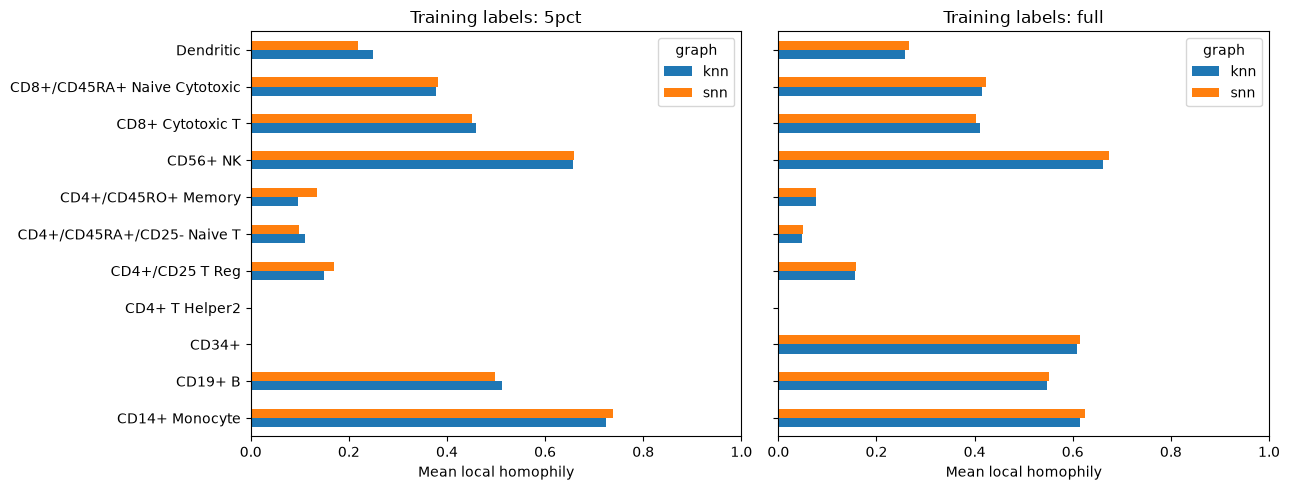

In [8]:
def audit_homophily(graph, labels):
    graph = checked_graph(graph)
    labels = np.asarray(labels)
    if labels.shape != (graph.shape[0],) or pd.isna(labels).any():
        raise ValueError("One nonmissing label per cell is required")
    names, codes = np.unique(labels, return_inverse=True)
    degree = np.diff(graph.indptr)
    rows = np.repeat(np.arange(len(labels)), degree)
    same = codes[rows] == codes[graph.indices]
    same_count = np.bincount(rows, weights=same.astype(float), minlength=len(labels))
    same_weight = np.bincount(rows, weights=graph.data * same, minlength=len(labels))
    strength = np.asarray(graph.sum(axis=1)).ravel()
    local = np.divide(same_count, degree, out=np.full(len(labels), np.nan), where=degree > 0)
    records = []
    for c, name in enumerate(names):
        mask = codes == c
        endpoints, total_weight = degree[mask].sum(), strength[mask].sum()
        valid = mask & (degree > 0)
        records.append({"celltype": name, "cells": int(mask.sum()),
            "class_fraction": float(mask.mean()), "isolates": int((mask & (degree == 0)).sum()),
            "endpoint_homophily": float(same_count[mask].sum() / endpoints) if endpoints else np.nan,
            "mean_local_homophily": float(local[valid].mean()) if valid.any() else np.nan,
            "weighted_endpoint_homophily": float(same_weight[mask].sum() / total_weight) if total_weight else np.nan})
    counts, n = np.bincount(codes), len(labels)
    global_result = {"edge_homophily": float(same.mean()) if len(same) else np.nan,
        "weighted_edge_homophily": float(np.dot(graph.data, same) / graph.data.sum()) if graph.nnz else np.nan,
        "random_label_expectation": float(np.sum(counts * (counts - 1)) / (n * (n - 1))) if n > 1 else np.nan}
    return global_result, pd.DataFrame(records), local

def homophily_table(graph, labels, name, budget):
    global_scores, table, _ = audit_homophily(graph, labels)
    degree = np.diff(graph.indptr)
    strength = np.asarray(graph.sum(axis=1)).ravel()
    rows = np.repeat(np.arange(len(labels)), degree)
    same = labels[rows] == labels[graph.indices]
    same_weight = np.bincount(rows, weights=graph.data * same, minlength=len(labels))
    local_weighted = np.divide(same_weight, strength, out=np.full(len(labels), np.nan), where=strength > 0)
    for idx, record in table.iterrows():
        select = labels == record.celltype
        table.loc[idx, "contributing_cells"] = int((select & (degree > 0)).sum())
        table.loc[idx, "eligible_endpoints"] = int(degree[select].sum())
        valid = select & (strength > 0)
        table.loc[idx, "mean_weighted_local_homophily"] = float(local_weighted[valid].mean()) if valid.any() else np.nan
    table["scope"] = "class"
    global_row = {"scope": "global", "celltype": "ALL", "cells": len(labels),
                  "eligible_edges": graph.nnz // 2, "contributing_cells": int((degree > 0).sum()),
                  "isolates": int((degree == 0).sum()), **global_scores}
    table = pd.concat([pd.DataFrame([global_row]), table], ignore_index=True)
    table.insert(0, "graph", name); table.insert(1, "budget", budget)
    return table

audit_tables = {}
for budget, mask in budget_masks.items():
    labels = class_names[training_labels[budget][mask]]
    table = pd.concat([homophily_table(a[mask][:, mask], labels, name, budget)
                       for name, a in graphs.items()], ignore_index=True)
    table.to_csv(OUT / f"analysis/homophily_{budget}.csv", index=False)
    audit_tables[budget] = table
    print("Label budget:", budget)
    display(table.loc[table.scope == "class", ["graph", "celltype", "cells", "contributing_cells", "mean_local_homophily"]])

# A--A--B plus isolated B: local values 1, 1/2, 0, NaN.
example = sp.csr_matrix(([1., 1., 1., 1.], ([0, 1, 1, 2], [1, 0, 2, 1])), shape=(4, 4))
global_example, class_example, local_example = audit_homophily(example, ["A", "A", "B", "B"])
assert global_example["edge_homophily"] == 0.5
assert class_example.set_index("celltype").loc["A", "mean_local_homophily"] == 0.75
assert np.isnan(local_example[-1])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, budget in zip(axes, budget_masks):
    table = audit_tables[budget]
    table = table[(table.scope == "class") & table.graph.isin(["knn", "snn"])]
    table.pivot(index="celltype", columns="graph", values="mean_local_homophily").plot.barh(ax=ax)
    ax.set(title=f"Training labels: {budget}", xlabel="Mean local homophily", xlim=(0, 1), ylabel="")
fig.tight_layout(); plt.show()

## 7. Export inputs for GNN training

Save to **`data/graph_engineering/`** with the same cell order throughout.

Each budget gets masks, targets and scaled features. Fit its scaler on selected training cells only, then transform all cells. The matching MLP uses these features. Graphs use the original PCA coordinates.

Training targets are **-1** outside `labelled_train`. Validation targets are separate and test targets are not exported. Compute loss only on `labelled_train`.

Reuse matching graph exports. Changes to inputs, settings or code rebuild generated files in the same folder. Back up results before changing an experiment. See the [output summary](markdown/graph_engineering_walkthrough.md#where-to-find-the-outputs).

In [9]:
pd.DataFrame({"cell_id": meta.index.astype(str)}).to_csv(OUT / "cell_ids.csv", index=False)
write_json(OUT / "class_names.json", class_names.tolist())
np.save(OUT / "X_pca.npy", X)
scalers, scaled_features = {}, {}
for budget, mask in budget_masks.items():
    folder = OUT / f"labels_{budget}"
    scaler = StandardScaler().fit(X[mask])
    scaled = scaler.transform(X).astype(np.float32)
    assert scaler.n_samples_seen_ == mask.sum()
    np.testing.assert_allclose(scaler.mean_, X[mask].mean(axis=0, dtype=np.float64))
    scalers[budget], scaled_features[budget] = scaler, scaled
    np.savez_compressed(folder / "masks.npz", train_pool=train_pool, labelled_train=mask,
                        validation=val_mask, test=test_mask)
    np.save(folder / "training_labels.npy", training_labels[budget])
    np.save(folder / "validation_labels.npy", validation_labels)
    np.save(folder / "X_scaled.npy", scaled)
    joblib.dump(scaler, folder / "scaler.joblib")

export_files = ["cell_ids.csv", "class_names.json", "X_pca.npy"]
export_files += [str(p.relative_to(OUT)) for directory in ["graphs", "labels_5pct", "labels_full", "analysis"]
                 for p in sorted((OUT / directory).iterdir()) if p.is_file()]
manifest = {"spec": export_spec, "nodes": len(X), "classes": len(class_names),
            "labelled_counts": {name: int(mask.sum()) for name, mask in budget_masks.items()},
            "array_order": "cell_ids.csv", "features": f"{N_PCS} PCs; X_scaled fitted on labelled_train per budget",
            "test_ground_truth_exported": False, "graph_exports_complete": True,
            "baselines_complete": False,
            "files_sha256": {p: file_digest(OUT / p) for p in export_files}}
write_json(manifest_path, manifest)
print("GNN inputs saved:", OUT.relative_to(ROOT))

GNN inputs saved: data/graph_engineering


## 8. MLP baseline

Train on PCA features without graph connections. Use one ReLU hidden layer, Adam and class-balanced sample weights.

Compare **64 and 128 hidden units** at each budget. Select the checkpoint with the highest validation macro-F1, which weights each type equally. Stop after 25 epochs without improvement or 200 total epochs.

Repeat at seeds **42, 123 and 2024**, the GNN seeds, and report mean and sample standard deviation. Seed 42's model is the exported MLP that later notebooks load.

In [10]:
def train_library_mlp(x_train, y_train, x_val, y_val, classes, *, settings,
                      max_epochs=200, patience=25, balance_classes=True):
    if len(x_train) != len(y_train) or len(x_val) != len(y_val):
        raise ValueError("Feature/label lengths differ")
    if max_epochs < 1 or patience < 1 or len(x_train) == 0 or len(x_val) == 0:
        raise ValueError("Need positive epochs/patience and nonempty train/validation")
    if set(np.unique(y_train)) != set(classes):
        raise ValueError("Every class must have a training example")
    if settings.get("early_stopping", False):
        raise ValueError("Use the shared validation set, not internal early stopping")
    scaler = StandardScaler().fit(x_train)
    xt = scaler.transform(x_train).astype(np.float32)
    xv = scaler.transform(x_val).astype(np.float32)
    sample_weight = compute_sample_weight("balanced", y_train) if balance_classes else None
    settings = dict(settings)
    if isinstance(settings.get("batch_size"), int):
        settings["batch_size"] = min(settings["batch_size"], len(x_train))
    model = MLPClassifier(**settings)
    best_model, best_score, best_epoch, stale, history = None, -np.inf, 0, 0, []
    with threadpool_limits(limits=CPU_THREADS):
        for epoch in range(1, max_epochs + 1):
            model.partial_fit(xt, y_train, classes=classes, sample_weight=sample_weight)
            prediction = model.predict(xv)
            score = f1_score(y_val, prediction, labels=classes, average="macro", zero_division=0)
            history.append({"epoch": epoch, "training_loss": float(model.loss_), "val_macro_f1": float(score)})
            if score > best_score + 1e-8:
                best_model, best_score, best_epoch, stale = copy.deepcopy(model), float(score), epoch, 0
            else:
                stale += 1
            if stale >= patience:
                break
    return {"model": best_model, "scaler": scaler, "best_epoch": best_epoch,
            "best_val_macro_f1": best_score, "history": pd.DataFrame(history)}

def prediction_report(truth, prediction):
    summary = {"accuracy": float(accuracy_score(truth, prediction)),
               "macro_f1": float(f1_score(truth, prediction, labels=class_ids, average="macro", zero_division=0))}
    report = classification_report(truth, prediction, labels=class_ids, target_names=class_names.tolist(),
                                   zero_division=0, output_dict=True)
    table = pd.DataFrame([{"celltype": name, **report[name]} for name in class_names])
    return summary, table, confusion_matrix(truth, prediction, labels=class_ids)

results, per_class_results, predictions, model_details = [], [], {}, {}
def record_validation(budget, model_name, prediction, seconds, details):
    prediction = np.asarray(prediction, dtype=np.int64)
    assert prediction.shape == (len(X),) and np.isin(prediction, class_ids).all()
    summary, table, cm = prediction_report(y_val, prediction[val_mask])
    result_key = budget + "__" + model_name
    results.append({"budget": budget, "model": model_name, "labelled_cells": int(budget_masks[budget].sum()),
                    "split": "validation", "seconds": seconds, **summary, **details})
    table.insert(0, "model", model_name); table.insert(0, "budget", budget)
    per_class_results.append(table)
    predictions[result_key] = prediction
    model_details[result_key] = details
    np.save(OUT / "results" / (result_key + "_predictions.npy"), prediction)
    np.save(OUT / "results" / (result_key + "_validation_confusion.npy"), cm)
    return summary

mlp_trials, mlp_seed_scores = [], []
for budget, mask in budget_masks.items():
    for seed in MLP_SEEDS:
        start = time.perf_counter()
        candidates = []
        for width in MLP_WIDTHS:
            fit = train_library_mlp(X[mask], training_labels[budget][mask], X[val_mask], y_val, class_ids,
                    settings={**MLP_SETTINGS, "hidden_layer_sizes": (width,), "random_state": seed},
                    max_epochs=MAX_EPOCHS, patience=PATIENCE, balance_classes=True)
            np.testing.assert_allclose(fit["scaler"].mean_, scalers[budget].mean_)
            mlp_trials.append({"budget": budget, "seed": seed, "width": width, "best_epoch": fit["best_epoch"],
                               "val_macro_f1": fit["best_val_macro_f1"]})
            fit["history"].to_csv(OUT / "results" / f"mlp_{budget}_seed{seed}_width{width}_history.csv", index=False)
            candidates.append((width, fit))
        width, best = max(candidates, key=lambda pair: pair[1]["best_val_macro_f1"])
        with threadpool_limits(limits=CPU_THREADS):
            pred = best["model"].predict(scaled_features[budget])
        # Later notebooks load one MLP per budget, so only the SEED run is exported and recorded.
        if seed == SEED:
            joblib.dump({"model": best["model"], "scaler": best["scaler"], "classes": class_names},
                        OUT / "models" / f"mlp_{budget}.joblib")
            summary = record_validation(budget, "mlp", pred, time.perf_counter() - start,
                                       {"width": width, "best_epoch": best["best_epoch"]})
        else:
            summary = prediction_report(y_val, pred[val_mask])[0]
        mlp_seed_scores.append({"budget": budget, "seed": seed, "width": width, **summary})
        print(budget, "MLP seed", seed, summary)
pd.DataFrame(mlp_trials).to_csv(OUT / "results/mlp_trials.csv", index=False)
mlp_seed_scores = pd.DataFrame(mlp_seed_scores)
mlp_seed_scores.to_csv(OUT / "results/mlp_seed_scores.csv", index=False)
display(pd.DataFrame(mlp_trials))
print(f"MLP validation across seeds {list(MLP_SEEDS)} (mean and sample std):")
display(mlp_seed_scores.groupby("budget")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(3))

5pct MLP seed 42 {'accuracy': 0.4755260750228728, 'macro_f1': 0.41030602140631645}


5pct MLP seed 123 {'accuracy': 0.4808630680085392, 'macro_f1': 0.41205882029996527}


5pct MLP seed 2024 {'accuracy': 0.46675815797499237, 'macro_f1': 0.4002426927201812}


full MLP seed 42 {'accuracy': 0.4632509911558402, 'macro_f1': 0.4444125697290197}


full MLP seed 123 {'accuracy': 0.46538578835010674, 'macro_f1': 0.43103969585671303}


full MLP seed 2024 {'accuracy': 0.4640134187252211, 'macro_f1': 0.43615185087269914}


,budget,seed,width,best_epoch,val_macro_f1
0,5pct,42,64,134,0.396812
1,5pct,42,128,43,0.410306
2,5pct,123,64,58,0.402667
3,5pct,123,128,80,0.412059
4,5pct,2024,64,75,0.399671
5,5pct,2024,128,39,0.400243
6,full,42,64,40,0.435209
7,full,42,128,28,0.444413
8,full,123,64,16,0.426233
9,full,123,128,55,0.431040


MLP validation across seeds [42, 123, 2024] (mean and sample std):


accuracy        macro_f1       
           mean    std     mean    std
budget                                
5pct      0.474  0.007    0.408  0.006
full      0.464  0.001    0.437  0.007

## 9. Label Propagation

Run scikit-learn's `LabelPropagation` on each saved graph through a custom kernel. Selected training labels stay fixed. All other labels start at **-1**.

Cells without a propagated signal receive the most frequent training class. Report this fallback rate, including components with no training labels.

The library normalises a graph copy and isolated labelled cells get a self-loop in that copy. Exported graphs stay unchanged. This implementation predicts only for the existing cells.

In [11]:
class FixedGraphKernel:
    def __init__(self, graph):
        self.graph = graph

    def __call__(self, left, right):
        expected = np.arange(self.graph.shape[0])[:, None]
        if not np.array_equal(left, expected) or not np.array_equal(right, expected):
            raise ValueError("FixedGraphKernel supports the fitted node order only")
        return self.graph.copy()


def propagate_labels(graph, available_labels, max_iter=2000, tol=1e-3):
    graph = checked_graph(graph)
    labels = np.asarray(available_labels)
    if labels.shape != (graph.shape[0],) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("Expected one encoded label per node")
    labelled = labels >= 0
    if not labelled.any() or np.any(labels < -1):
        raise ValueError("Need training labels and -1 for unavailable labels")
    _, component = connected_components(graph, directed=False)
    reachable = np.isin(component, np.unique(component[labelled]))
    majority = int(np.argmax(np.bincount(labels[labelled])))
    subgraph = graph[reachable][:, reachable].tocsr()
    isolated = np.diff(subgraph.indptr) == 0
    if isolated.any():
        subgraph = subgraph + sp.diags(isolated.astype(float))
    model = LabelPropagation(kernel=FixedGraphKernel(subgraph), max_iter=max_iter, tol=tol)
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=CPU_THREADS):
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(np.arange(subgraph.shape[0])[:, None], labels[reachable])
    probs = model.label_distributions_
    assert np.isfinite(probs).all()
    has_signal = probs.sum(axis=1) > 0
    fallback = ~reachable
    fallback[np.flatnonzero(reachable)[~has_signal]] = True
    prediction = np.full(len(labels), majority, dtype=np.int64)
    active = np.flatnonzero(reachable)[has_signal]
    prediction[active] = model.classes_[probs[has_signal].argmax(axis=1)]
    np.testing.assert_array_equal(prediction[labelled], labels[labelled])
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    info = {"iterations": int(model.n_iter_), "converged": converged,
            "reachable_fraction": float(reachable.mean()), "fallback_fraction": float(fallback.mean()),
            "fallback_class": majority}
    return prediction, fallback, info

# One seeded component, one unseeded component, and an isolated labelled node.
toy_graph = sp.csr_matrix(([1., 1., 1., 1.], ([0, 1, 2, 3], [1, 0, 3, 2])), shape=(5, 5))
toy_labels = np.array([0, -1, -1, -1, 1])
before = toy_graph.copy()
toy_prediction, toy_fallback, toy_info = propagate_labels(toy_graph, toy_labels)
np.testing.assert_array_equal(toy_prediction, [0, 0, 0, 0, 1])
np.testing.assert_array_equal(toy_fallback, [False, False, True, True, False])
assert (before != toy_graph).nnz == 0
print("Passed LP clamping, disconnected-component, isolate and graph-copy checks.")

for budget in budget_masks:
    for name in ["knn", "snn"]:
        start = time.perf_counter()
        pred, fallback, info = propagate_labels(graphs[name], training_labels[budget], LP_MAX_ITER, LP_TOL)
        info["validation_fallback_fraction"] = float(fallback[val_mask].mean())
        np.save(OUT / "results" / f"{budget}__lp_{name}_fallback.npy", fallback)
        write_json(OUT / "models" / f"lp_{name}_{budget}.json", info)
        summary = record_validation(budget, "lp_" + name, pred, time.perf_counter() - start, info)
        print(budget, name, summary, info)

Passed LP clamping, disconnected-component, isolate and graph-copy checks.


5pct knn {'accuracy': 0.4839890210430009, 'macro_f1': 0.3394510956506115} {'iterations': 366, 'converged': True, 'reachable_fraction': 1.0, 'fallback_fraction': 0.0, 'fallback_class': 8, 'validation_fallback_fraction': 0.0}


5pct snn {'accuracy': 0.45776151265629766, 'macro_f1': 0.3485378621552751} {'iterations': 525, 'converged': True, 'reachable_fraction': 0.9999695019671231, 'fallback_fraction': 3.049803287687944e-05, 'fallback_class': 8, 'validation_fallback_fraction': 7.624275693809088e-05}


full knn {'accuracy': 0.5375114364135407, 'macro_f1': 0.4097492579184006} {'iterations': 17, 'converged': True, 'reachable_fraction': 1.0, 'fallback_fraction': 0.0, 'fallback_class': 8, 'validation_fallback_fraction': 0.0}


full snn {'accuracy': 0.5079292467215615, 'macro_f1': 0.39911116459126406} {'iterations': 21, 'converged': True, 'reachable_fraction': 0.9999695019671231, 'fallback_fraction': 3.049803287687944e-05, 'fallback_class': 8, 'validation_fallback_fraction': 7.624275693809088e-05}


## 10. Compare validation results

Compare **MLP, LP on k-NN and LP on SNN** at both budgets. Report accuracy, macro-F1 and per-type scores. Support counts validation cells of each type. A few predictions can noticeably change rare-type recall.

MLP uses validation to select width and checkpoint. LP settings are fixed. MLP timing includes both widths, so runtimes are not directly comparable.

MLP varies across its three seeds; LP is deterministic, so one run measures it. GNN experiments are still needed to compare the graphs for message passing.

,budget,model,labelled_cells,accuracy,macro_f1,seconds
0,5pct,mlp,1971,0.475526,0.410306,1.639068
1,full,mlp,39346,0.463251,0.444413,6.565918
2,5pct,lp_knn,1971,0.483989,0.339451,4.344203
3,5pct,lp_snn,1971,0.457762,0.348538,4.848455
4,full,lp_knn,39346,0.537511,0.409749,0.254579
5,full,lp_snn,39346,0.507929,0.399111,0.310472


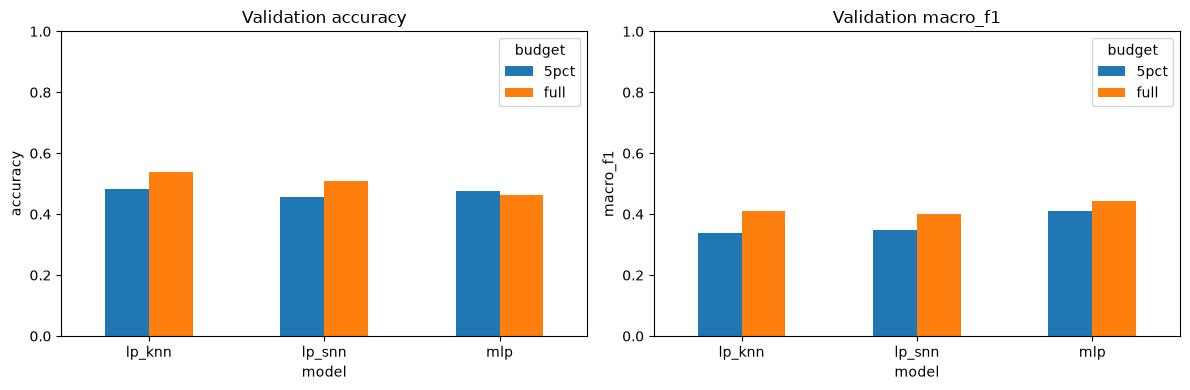

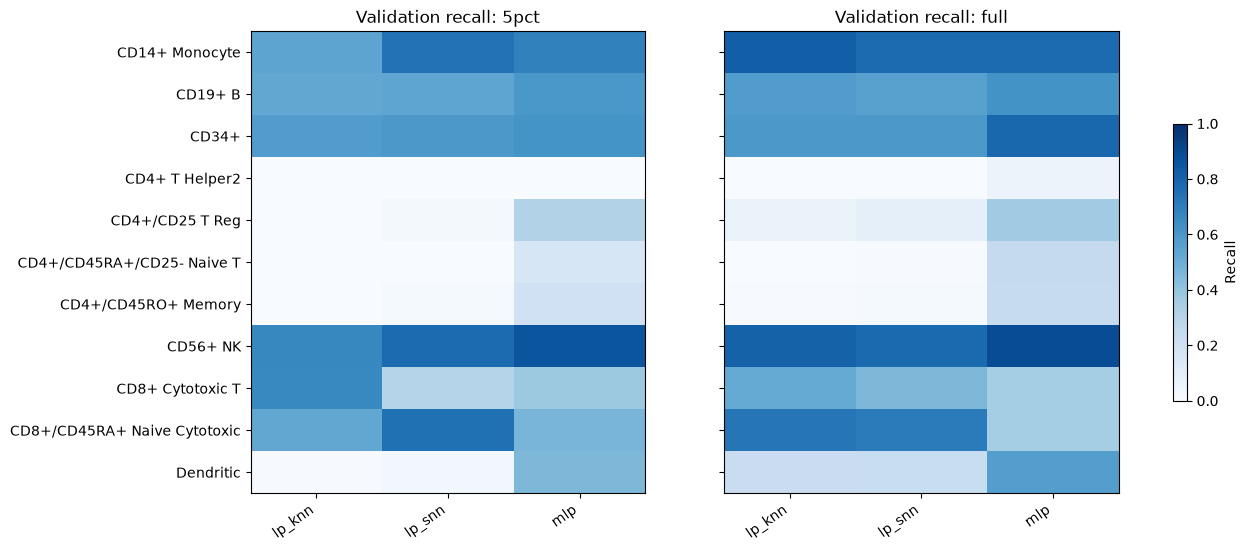

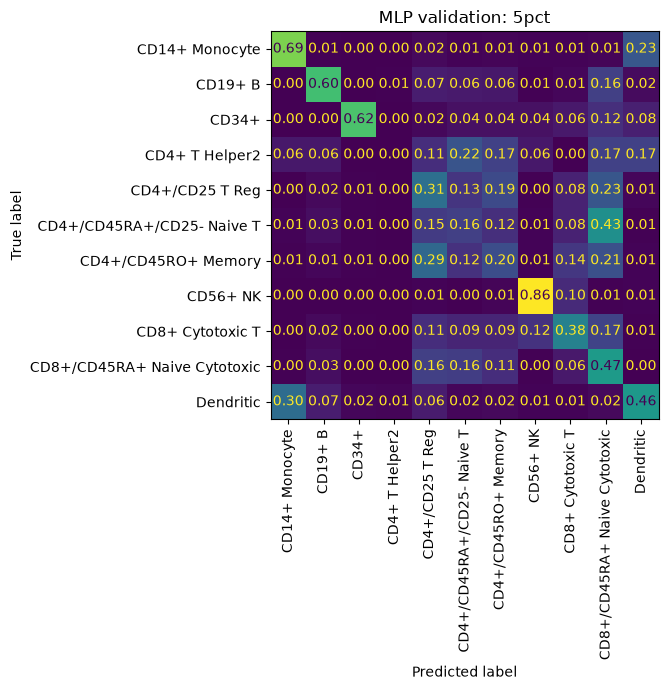

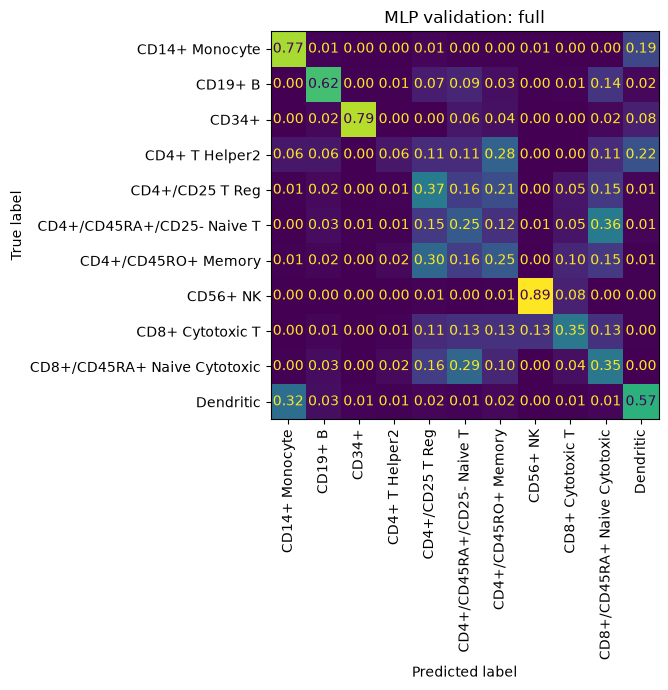

In [12]:
validation_results = pd.DataFrame(results)
validation_per_class = pd.concat(per_class_results, ignore_index=True)
validation_results.to_csv(OUT / "results/validation_results.csv", index=False)
validation_per_class.to_csv(OUT / "results/validation_per_class.csv", index=False)
display(validation_results[["budget", "model", "labelled_cells", "accuracy", "macro_f1", "seconds"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    validation_results.pivot(index="model", columns="budget", values=metric).plot.bar(ax=ax, rot=0)
    ax.set(title="Validation " + metric, ylabel=metric, ylim=(0, 1))
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, budget in zip(axes, budget_masks):
    table = validation_per_class[validation_per_class.budget == budget].pivot(index="celltype", columns="model", values="recall")
    im = ax.imshow(table.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
    ax.set_xticks(np.arange(len(table.columns)), table.columns, rotation=35, ha="right")
    ax.set_yticks(np.arange(len(table.index)), table.index)
    ax.set_title("Validation recall: " + budget)
fig.colorbar(im, ax=axes.tolist(), label="Recall", shrink=0.6)
plt.show()
# Per-model confusion matrices are saved; display the selected MLP for each budget.
for budget in budget_masks:
    cm = confusion_matrix(y_val, predictions[budget + "__mlp"][val_mask], labels=class_ids)
    normalised = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True)>0)
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(normalised, display_labels=class_names).plot(ax=ax, xticks_rotation=90, values_format=".2f", colorbar=False)
    ax.set_title("MLP validation: " + budget)
    fig.tight_layout(); plt.show()
manifest["baselines_complete"] = len(results) == 6
manifest["completed_methods"] = validation_results[["budget", "model"]].to_dict(orient="records")
manifest["files_sha256"].update({str(p.relative_to(OUT)): file_digest(p)
    for directory in [OUT / "results", OUT / "models"] for p in sorted(directory.rglob("*")) if p.is_file()})
write_json(manifest_path, manifest)

## 11. Final test evaluation

Keep **`EVALUATE_TEST=False`** until models and settings are fixed. Then score the planned models together. Do not tune on test scores or refit on validation labels for this comparison.

Record settings and predictions before scoring. Repeated scoring reuses the record. Changed settings or predictions are blocked for the same test split. This does not undo earlier test inspection.

In [13]:
if EVALUATE_TEST:
    if not manifest["baselines_complete"]:
        raise RuntimeError("Complete the planned method set before final test scoring.")
    frozen_id = digest_json({"configuration": configuration_id,
                            "predictions": {key: digest_array(value) for key, value in predictions.items()}})
    record_dir = ROOT / "data/evaluation_records"
    record_dir.mkdir(parents=True, exist_ok=True)
    record_path = record_dir / ("graph_engineering_" + digest_json(meta.index[test_mask].tolist())[:16] + ".json")
    if record_path.exists():
        record = json.loads(record_path.read_text())
        if record["frozen_id"] != frozen_id:
            raise RuntimeError("This test split was already opened for different predictions or settings.")
    else:
        record = {"frozen_id": frozen_id, "status": "opened"}
        write_json(record_path, record)
    if record["status"] != "complete":
        test_truth = encoder.transform(meta.loc[test_mask, "celltype"])
        scores, reports = [], []
        for key, pred in predictions.items():
            summary, table, _ = prediction_report(test_truth, pred[test_mask])
            scores.append({"run": key, **summary})
            table.insert(0, "run", key); reports.extend(table.to_dict(orient="records"))
        record.update(status="complete", scores=scores, per_class=reports)
        write_json(record_path, record)
    pd.DataFrame(record["scores"]).to_csv(OUT / "results/test_results.csv", index=False)
    pd.DataFrame(record["per_class"]).to_csv(OUT / "results/test_per_class.csv", index=False)
    display(pd.DataFrame(record["scores"]))
else:
    print("Test scoring OFF. No test labels used for fitting, propagation, graph audits or model selection.")

Test scoring OFF. No test labels used for fitting, propagation, graph audits or model selection.


## 12. Load the exports for GNN training

Choose a budget and graph. Keep `cell_ids.csv` order. Use all nodes for message passing and only **`labelled_train`** for supervised loss.

The example loads features, masks and targets and prepares edge indices and weights. Preserve SNN weights. Handle self-loops and normalisation once in the GNN.

For PyTorch, use integer indices and labels, boolean masks, and floating-point features and weights. See the [walkthrough](markdown/graph_engineering_walkthrough.md) for loading instructions.

In [14]:
# Run from the repository root in your GNN notebook.
export_dir = Path("data/graph_engineering")
budget_dir = export_dir / "labels_5pct"
cell_ids = pd.read_csv(export_dir / "cell_ids.csv", dtype=str)["cell_id"].to_numpy()
node_features = np.load(budget_dir / "X_scaled.npy", allow_pickle=False)
adjacency = sp.load_npz(export_dir / "graphs/snn_adjacency.npz").tocoo()
with np.load(budget_dir / "masks.npz", allow_pickle=False) as saved:
    masks = {name: saved[name] for name in saved.files}
train_targets = np.load(budget_dir / "training_labels.npy", allow_pickle=False)
val_targets = np.load(budget_dir / "validation_labels.npy", allow_pickle=False)
edge_index = np.stack([adjacency.row, adjacency.col]).astype(np.int64)
edge_weight = adjacency.data.astype(np.float32)
assert adjacency.shape == (len(cell_ids), len(cell_ids))
assert node_features.shape == (len(cell_ids), N_PCS)
assert (train_targets[~masks["labelled_train"]] == -1).all()
assert (val_targets[~masks["validation"]] == -1).all()
print("Features:", node_features.shape, "edge_index:", edge_index.shape)
print("Use loss(logits[labelled_train], train_targets[labelled_train]).")
print("Export folder:", export_dir)

Features: (65578, 50) edge_index: (2, 1332710)
Use loss(logits[labelled_train], train_targets[labelled_train]).
Export folder: data/graph_engineering
